# A CNN + Transformer hybrid for isolated sign recognition in PyTorch

Live app: [https://swapnil007-curious.github.io/manuvox/](https://swapnil007-curious.github.io/manuvox/) · GitHub: [https://github.com/Swapnil007-Curious/manuvox](https://github.com/Swapnil007-Curious/manuvox) · Paper: link coming soon

This notebook builds and trains the model that ManuVox runs in the browser: a 3.4M-parameter network that alternates depthwise temporal convolutions with transformer blocks, on 588 features per frame computed inside the model. It trains on a Kaggle GPU with a signer-independent split, so the four test signers are never seen in training, then looks at which signs, which signers and which sign pairs it gets wrong. The repository trains the same model for 150 epochs and reports 68.5% top-1 (mean of three seeds, sd 0.2) on these four test signers (`results/model_selection.md`); this run uses 80 epochs to stay well inside Kaggle's limits.

Data: the `asl-signs` competition files only (CC BY 4.0). Needs a GPU (T4), about 35 minutes on Kaggle. Part 4 of a 5-notebook series.

Contents

1. Setup and data
2. A signer-independent split
3. Features inside the model
4. The hybrid architecture
5. Augmentation and the training recipe
6. Training
7. Test results on unseen signers
8. Per-sign accuracy
9. The most common confusions
10. What we found

## 1. Setup and data

Preprocessing is shared with the rest of the series (notebook 1 explains the data): frames without a hand are dropped, left-dominant sequences are mirrored so the dominant hand is always in the right-hand block, coordinates are centred on the shoulders and divided by the shoulder width, and every sequence is resampled to 32 frames. One frame becomes 120 numbers: x and y for 59 landmarks (both hands and pose points 0-16) plus two hand-presence flags.

In [1]:
import json
import math
import os
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from cycler import cycler
from IPython.display import Image, Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# Kaggle paths. The environment variables only matter when the notebook runs outside Kaggle.
INPUT_DIR = Path(os.environ.get("KAGGLE_INPUT_DIR", "/kaggle/input"))
WORK_DIR = Path(os.environ.get("KAGGLE_WORKING_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
# FAST=1 keeps a few sequences per sign, for testing the notebook end to end on a laptop.
FAST = os.environ.get("MANUVOX_FAST", "0") == "1"
FAST_PER_SIGN = 24  # Sequences per sign in FAST mode (250 signs, so about 6,000 sequences).
SEED = 42  # One seed for every random choice in the notebook.
N_WORKERS = os.cpu_count() or 1  # Kaggle gives 4 CPUs.

random.seed(SEED)
np.random.seed(SEED)

# Plot style: a colour-blind-safe categorical palette (checked for deutan, protan and tritan
# separation), one blue ramp for magnitudes, hairline grids.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW = PALETTE[:4]
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"]
)
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.prop_cycle": cycler(color=PALETTE),
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlecolor": INK,
        "axes.titlelocation": "left",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "legend.frameon": False,
        "figure.dpi": 100,
        "font.size": 10,
    }
)


def takeaway(text):
    """Print the one-line reading of the plot above, written from this run's numbers."""
    display(Markdown(f"Takeaway: {text}"))


def save_cover(fig, name="cover.png"):
    """Save a 1280x720 copy of ``fig`` as the notebook's cover image."""
    fig.set_size_inches(12.8, 7.2)
    fig.savefig(WORK_DIR / name, dpi=100)


print(f"FAST mode: {FAST}; {N_WORKERS} CPUs")
if FAST:
    print(f"FAST is a test run on up to {FAST_PER_SIGN} sequences per sign with short training: "
          "every number below comes from that sample, not from the full data.")

FAST mode: True; 4 CPUs
FAST is a test run on up to 24 sequences per sign with short training: every number below comes from that sample, not from the full data.


In [2]:
import multiprocessing as mp

COMPETITION = "asl-signs"
# Every frame of a sequence file holds 543 rows in this order (checked on a sample below).
BLOCKS = {"face": 468, "left_hand": 21, "pose": 33, "right_hand": 21}
ROWS_PER_FRAME = sum(BLOCKS.values())
LEFT_START, POSE_START, RIGHT_START = 468, 489, 522
# Selected landmarks: left hand 0-20, right hand 0-20, then pose 0-16 (nose, eyes, ears, mouth
# corners, shoulders, elbows, wrists). The face mesh is dropped. L = 59.
POSE_POINTS = list(range(17))
SELECTED = np.r_[
    LEFT_START : LEFT_START + 21, RIGHT_START : RIGHT_START + 21, POSE_START + np.array(POSE_POINTS)
]
N_LANDMARKS = len(SELECTED)
LEFT, RIGHT = slice(0, 21), slice(21, 42)
NOSE, L_SHOULDER, R_SHOULDER, L_WRIST, R_WRIST = (42 + i for i in (0, 11, 12, 15, 16))
# Left/right pose pairs that a mirror swaps (eyes, ears, mouth corners, shoulders, elbows, wrists).
POSE_SWAP_PAIRS = [(1, 4), (2, 5), (3, 6), (7, 8), (9, 10), (11, 12), (13, 14), (15, 16)]
NUM_FRAMES = 32  # Every sequence is resampled to this many frames.
MIN_HAND_FRAMES = 3  # Sequences with fewer frames showing a hand are dropped.
FRAME_DIM = 2 * N_LANDMARKS + 2  # x, y per landmark, then left and right hand presence.


def find_competition_dir(root=INPUT_DIR, name=COMPETITION):
    """Return the folder holding train.csv and the sign map, wherever Kaggle mounts it."""
    for candidate in (root / name, root / "competitions" / name):
        if (candidate / "train.csv").is_file():
            return candidate
    for folder, subfolders, files in os.walk(root, followlinks=True):
        subfolders[:] = [s for s in subfolders if s != "train_landmark_files"]
        if "train.csv" in files and "sign_to_prediction_index_map.json" in files:
            return Path(folder)
    raise FileNotFoundError("Add the competition data: Add Input > Competitions > asl-signs")


def load_table(data_dir, fast=FAST):
    """train.csv with integer labels; in FAST mode, up to FAST_PER_SIGN files per sign on disk."""
    table = pd.read_csv(data_dir / "train.csv", keep_default_na=False)
    sign_map = json.loads((data_dir / "sign_to_prediction_index_map.json").read_text())
    table["label"] = table["sign"].map(sign_map).astype(int)
    if fast:
        on_disk = table["path"].map(lambda p: (data_dir / p).is_file())
        table = table[on_disk].groupby("sign", sort=False).head(FAST_PER_SIGN)
    return table.reset_index(drop=True), sign_map


def check_layout(paths):
    """Confirm each file stores whole frames of 543 rows in the fixed block order."""
    types = np.repeat(list(BLOCKS), list(BLOCKS.values()))
    index = np.concatenate([np.arange(n) for n in BLOCKS.values()])
    for path in paths:
        df = pd.read_parquet(path, columns=["frame", "type", "landmark_index"])
        frames = len(df) // ROWS_PER_FRAME
        assert len(df) == frames * ROWS_PER_FRAME, f"{path.name}: partial frame"
        frame_ids = df["frame"].to_numpy().reshape(frames, ROWS_PER_FRAME)
        assert (frame_ids == frame_ids[:, :1]).all(), f"{path.name}: frames interleaved"
        assert (np.diff(frame_ids[:, 0]) > 0).all(), f"{path.name}: frames out of order"
        assert (df["type"].to_numpy().reshape(frames, -1) == types).all(), f"{path.name}: types"
        assert (df["landmark_index"].to_numpy().reshape(frames, -1) == index).all()
    return len(paths)


def read_frames(path, columns=("x", "y")):
    """All 543 landmarks of one file as a (frames, 543, len(columns)) float32 array, NaN = missing."""
    table = pq.read_table(path, columns=list(columns))
    values = [table.column(c).to_numpy().astype(np.float32) for c in columns]
    return np.stack(values, axis=-1).reshape(-1, ROWS_PER_FRAME, len(columns))


def read_xy(path):
    """The 59 selected landmarks of one file, (frames, 59, 2): x and y as fractions of the frame."""
    return read_frames(path)[:, SELECTED]


# Worker processes are forked (Linux, as on Kaggle); elsewhere the work runs in this process.
WORKERS_USED = N_WORKERS if N_WORKERS > 1 and "fork" in mp.get_all_start_methods() else 1


def parallel_map(function, items, chunksize=32):
    """Map over items with one forked process per CPU (Linux, as on Kaggle), else in a loop."""
    if WORKERS_USED > 1:
        with mp.get_context("fork").Pool(N_WORKERS) as pool:
            return list(pool.imap(function, items, chunksize=chunksize))
    return [function(item) for item in items]

In [3]:
def hand_presence(xy):
    """(frames, 2) booleans: is the left / right hand present (all 21 points finite)?"""
    finite = np.isfinite(xy).all(axis=-1)
    return np.stack([finite[:, LEFT].all(axis=1), finite[:, RIGHT].all(axis=1)], axis=1)


def mirror_permutation():
    """Landmark order after a mirror: hands swap blocks and each left/right pose pair swaps."""
    order = np.arange(N_LANDMARKS)
    order[LEFT], order[RIGHT] = np.arange(21, 42), np.arange(21)
    for a, b in POSE_SWAP_PAIRS:
        order[[42 + a, 42 + b]] = [42 + b, 42 + a]
    return order


MIRROR = mirror_permutation()


def mirror(xy):
    """Mirror a sequence: x -> 1 - x and every left/right landmark pair trades places."""
    out = xy[:, MIRROR].copy()
    out[..., 0] = 1.0 - out[..., 0]
    return out


def normalisation(xy):
    """(centre, scale): median shoulder midpoint and shoulder width; the hands if no shoulders."""
    left, right = xy[:, L_SHOULDER], xy[:, R_SHOULDER]
    both = np.isfinite(left).all(axis=1) & np.isfinite(right).all(axis=1)
    if both.any():
        centre = np.nanmedian(0.5 * (left + right), axis=0)
        width = np.hypot(left[:, 0] - right[:, 0], left[:, 1] - right[:, 1])
        return centre, float(np.nanmedian(width))
    hands = xy[:, :42].reshape(-1, 2)
    spread = np.nanmax(hands, axis=0) - np.nanmin(hands, axis=0)
    return np.nanmean(hands, axis=0), float(spread.max())


def resample(xy, num_frames=NUM_FRAMES):
    """Linear resampling over the frame index, between finite values of each coordinate only."""
    t = len(xy)
    flat = xy.reshape(t, -1).astype(np.float64)
    position = np.linspace(0.0, t - 1, num_frames)
    out = np.full((num_frames, flat.shape[1]), np.nan)
    finite = np.isfinite(flat)
    full = finite.all(axis=0)  # Columns without gaps: one vectorised interpolation.
    low = np.floor(position).astype(int)
    high = np.minimum(low + 1, t - 1)
    weight = (position - low)[:, None]
    out[:, full] = flat[low][:, full] * (1.0 - weight) + flat[high][:, full] * weight
    source = np.arange(t)
    for column in np.flatnonzero(~full & finite.any(axis=0)):
        ok = finite[:, column]
        out[:, column] = np.interp(
            position, source[ok], flat[ok, column], left=np.nan, right=np.nan
        )
    return out.reshape(num_frames, *xy.shape[1:])


def preprocess(xy):
    """Raw (frames, 59, 2) landmarks -> ((32, 120) float32 model input, info), or (None, info).

    Frames without a hand are dropped; a left-dominant sequence is mirrored so the dominant
    hand is always in the right-hand block; coordinates are centred on the shoulders and divided
    by the shoulder width; then 32 frames are resampled and missing points become 0.0.
    """
    info = {"t_raw": len(xy), "t_kept": 0, "mirrored": False}
    present = hand_presence(xy)
    keep = present.any(axis=1)
    xy, present = xy[keep], present[keep]
    info["t_kept"] = len(xy)
    if len(xy) < MIN_HAND_FRAMES:
        return None, info
    if present[:, 0].sum() > present[:, 1].sum():  # Left hand seen in more frames: mirror.
        xy, present = mirror(xy), present[:, ::-1]
        info["mirrored"] = True
    centre, scale = normalisation(xy)
    if not np.isfinite(scale) or scale < 1e-6:
        return None, info
    coords = resample((xy - centre) / scale)
    nearest = np.floor(np.linspace(0.0, len(xy) - 1, NUM_FRAMES) + 0.5).astype(int)
    frames = np.concatenate(
        [np.nan_to_num(coords, nan=0.0).reshape(NUM_FRAMES, -1), present[nearest]], axis=1
    )
    return frames.astype(np.float32), info


def _load_one(path):
    features, info = preprocess(read_xy(path))
    return (None if features is None else features.astype(np.float16)), info


def build_features(table, data_dir):
    """Preprocess every row of ``table``: returns (X float16 (n, 32, 120), kept rows, info)."""
    started = time.perf_counter()
    results = parallel_map(_load_one, [data_dir / p for p in table["path"]])
    info = pd.DataFrame([r[1] for r in results])
    kept = np.array([r[0] is not None for r in results])
    X = np.stack([r[0] for r in results if r[0] is not None])
    rows = table[kept].reset_index(drop=True)
    print(
        f"preprocessed {len(table):,} sequences in {time.perf_counter() - started:.0f} s: "
        f"{kept.sum():,} kept, {(~kept).sum():,} dropped (fewer than {MIN_HAND_FRAMES} hand frames)"
    )
    return X, rows, info.assign(kept=kept)


def signer_split(rows, n_test=4, n_val=3, seed=SEED):
    """Assign whole participants to test, val and train (the repository's seed-42 split)."""
    participants = np.random.default_rng(seed).permutation(np.unique(rows["participant_id"]))
    test, val = participants[:n_test], participants[n_test : n_test + n_val]
    split = np.where(
        rows["participant_id"].isin(test), "test", np.where(rows["participant_id"].isin(val), "val", "train")
    )
    return split, sorted(test.tolist()), sorted(val.tolist())

In [4]:
import torch
from torch import nn
from torch.nn import functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # A T4 on Kaggle; CPU works for FAST runs.
EPOCHS = 3 if FAST else 80  # The repository's recipe runs 150 with early stopping.
LR = 5e-4
EMA_DECAY = 0.99 if FAST else 0.999  # FAST runs too few steps for 0.999.

DATA_DIR = find_competition_dir()
table, sign_map = load_table(DATA_DIR)
labels = {index: sign for sign, index in sign_map.items()}
X, rows, _ = build_features(table, DATA_DIR)

preprocessed 6,000 sequences in 23 s: 5,536 kept, 464 dropped (fewer than 3 hand frames)


## 2. A signer-independent split

Whole signers go to one split: 4 for test, 3 for validation and the other 14 for training. Notebook 3 shows why a random split would overstate accuracy. With seed 42 this is the repository's split, so the numbers here are comparable with its results.

In [5]:
split, test_signers, val_signers = signer_split(rows)
print(f"test signers {test_signers}\nval signers  {val_signers}")
display(pd.Series(split).value_counts().rename("sequences").to_frame())


def tensors(name):
    """Features and labels of one split, on the GPU."""
    mask = split == name
    return torch.from_numpy(X[mask]).to(DEVICE), torch.from_numpy(rows["label"].to_numpy()[mask]).long().to(DEVICE)


(x_train, y_train), (x_val, y_val), (x_test, y_test) = (tensors(s) for s in ("train", "val", "test"))
test_rows = rows[split == "test"].reset_index(drop=True)

test signers [30680, 37779, 49445, 62590]
val signers  [27610, 34503, 37055]


,sequences
train,3725
test,1006
val,805


## 3. Features inside the model

The model computes its own features from the 120 raw numbers per frame, so the exported ONNX file (notebook 5) carries them and the browser only has to supply landmarks. Per frame:

- the 118 coordinates, their velocity (118) and acceleration (118);
- the 210 pairwise distances between the dominant hand's 21 points, which describe handshape regardless of where the hand is;
- 24 distances from the dominant wrist and fingertips to the nose, the mouth centre and both shoulders, which place the hand on the body.

That is 588 features. A missing point is stored as (0, 0), and any feature that involves a missing point is 0. Each feature is standardised with the mean and standard deviation of the training split.

In [6]:
import itertools

import torch
from torch import nn
from torch.nn import functional as F

HAND_PAIRS = list(itertools.combinations(range(21), 2))  # 210 point pairs of one hand.
FINGER_POINTS = (0, 4, 8, 12, 16, 20)  # Wrist and the five fingertips.
COORDS = 2 * N_LANDMARKS  # 118 coordinates per frame.


class FeatureBlock(nn.Module):
    """(B, 32, 120) frames -> (B, 32, 588) standardised features, inside the model.

    Features: coordinates, velocity and acceleration of all 59 points, the 210 pairwise distances
    of the dominant (right-block) hand, and 24 distances from its wrist and fingertips to the
    nose, mouth centre and shoulders. A point is missing when x == y == 0, and anything derived
    from a missing point is 0. Living inside the model means the ONNX export carries it too.
    """

    def __init__(self):
        super().__init__()
        self.output_dim = 3 * COORDS + len(HAND_PAIRS) + len(FINGER_POINTS) * 4
        first, second = zip(*HAND_PAIRS)
        self.register_buffer("pair_a", torch.tensor(first) + 21, persistent=False)
        self.register_buffer("pair_b", torch.tensor(second) + 21, persistent=False)
        self.register_buffer("fingers", torch.tensor(FINGER_POINTS) + 21, persistent=False)
        face = [NOSE, 42 + 9, 42 + 10, L_SHOULDER, R_SHOULDER]  # Nose, mouth corners, shoulders.
        self.register_buffer("targets", torch.tensor(face), persistent=False)
        self.register_buffer("mean", torch.zeros(self.output_dim))
        self.register_buffer("std", torch.ones(self.output_dim))

    def raw(self, x):
        b, t = x.shape[:2]
        p = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
        ok = ((p[..., 0] != 0) | (p[..., 1] != 0)).to(p.dtype)
        step = (p[:, 1:] - p[:, :-1]) * (ok[:, 1:] * ok[:, :-1]).unsqueeze(-1)
        velocity = torch.cat([torch.zeros_like(step[:, :1]), step], dim=1)
        second = (p[:, 2:] - 2 * p[:, 1:-1] + p[:, :-2]) * (ok[:, 2:] * ok[:, 1:-1] * ok[:, :-2]).unsqueeze(-1)
        acceleration = torch.cat([torch.zeros_like(second[:, :2]), second], dim=1)
        shape = distances(
            p.index_select(2, self.pair_a),
            p.index_select(2, self.pair_b),
            ok.index_select(2, self.pair_a) * ok.index_select(2, self.pair_b),
        )
        tg, tg_ok = p.index_select(2, self.targets), ok.index_select(2, self.targets)
        mouth = 0.5 * (tg[:, :, 1:2] + tg[:, :, 2:3])
        anchors = torch.cat([tg[:, :, :1], mouth, tg[:, :, 3:]], dim=2)
        anchors_ok = torch.cat([tg_ok[:, :, :1], tg_ok[:, :, 1:2] * tg_ok[:, :, 2:3], tg_ok[:, :, 3:]], dim=2)
        hand, hand_ok = p.index_select(2, self.fingers), ok.index_select(2, self.fingers)
        to_body = distances(
            hand.unsqueeze(3), anchors.unsqueeze(2), hand_ok.unsqueeze(3) * anchors_ok.unsqueeze(2)
        )
        return torch.cat(
            [
                x[..., :COORDS],
                velocity.reshape(b, t, COORDS),
                acceleration.reshape(b, t, COORDS),
                shape,
                to_body.reshape(b, t, -1),
            ],
            dim=-1,
        )

    def forward(self, x):
        return (self.raw(x) - self.mean) / self.std.clamp_min(1e-6)


class SimpleFeatures(nn.Module):
    """Coordinates and velocity only, (B, 32, 236): the cheaper input of the temporal CNN."""

    def __init__(self):
        super().__init__()
        self.output_dim = 2 * COORDS
        self.register_buffer("mean", torch.zeros(self.output_dim))
        self.register_buffer("std", torch.ones(self.output_dim))

    def raw(self, x):
        b, t = x.shape[:2]
        p = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
        ok = ((p[..., 0] != 0) | (p[..., 1] != 0)).to(p.dtype)
        step = (p[:, 1:] - p[:, :-1]) * (ok[:, 1:] * ok[:, :-1]).unsqueeze(-1)
        velocity = torch.cat([torch.zeros_like(step[:, :1]), step], dim=1)
        return torch.cat([x[..., :COORDS], velocity.reshape(b, t, COORDS)], dim=-1)

    def forward(self, x):
        return (self.raw(x) - self.mean) / self.std.clamp_min(1e-6)


def distances(a, b, valid):
    """Euclidean distance over the last axis, 0 where ``valid`` is 0."""
    return torch.sqrt(((a - b) ** 2).sum(dim=-1)) * valid


@torch.no_grad()
def fit_standardisation(block, x_train, chunk=4096):
    """Set the block's mean and std from every frame of the train split (float64 sums)."""
    total = torch.zeros(block.output_dim, dtype=torch.float64, device=x_train.device)
    squares = torch.zeros_like(total)
    for start in range(0, len(x_train), chunk):
        values = block.raw(x_train[start : start + chunk].float()).reshape(-1, block.output_dim).double()
        total += values.sum(dim=0)
        squares += (values**2).sum(dim=0)
    count = x_train.shape[0] * x_train.shape[1]
    mean = total / count
    block.mean.copy_(mean)
    block.std.copy_((squares / count - mean**2).clamp_min(0).sqrt().clamp_min(1e-6))

## 4. The hybrid architecture

The 588 features are projected to 256 channels. Three stages follow, each with two convolution blocks and one transformer block. A convolution block is a depthwise convolution over 17 frames with batch norm and SiLU, then a pointwise expansion to 512 channels and back, added to its input. Convolutions pick up local motion; the transformer block lets every frame attend to every other frame. Attention is written with plain `Linear` and `matmul`, which keeps the ONNX graph simple to quantise. The output is averaged over time and a linear head gives 250 logits. Head dropout of 0.4 switches on halfway through training.

In [7]:
class SelfAttention(nn.Module):
    """Multi-head self-attention written with Linear and MatMul, which export and quantise cleanly."""

    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.heads, self.head_dim = heads, dim // heads
        self.query, self.key, self.value, self.out = (nn.Linear(dim, dim) for _ in range(4))
        self.dropout = nn.Dropout(dropout)

    def split(self, x):
        return x.reshape(-1, x.shape[1], self.heads, self.head_dim).transpose(1, 2)

    def forward(self, x):
        q = self.split(self.query(x)) * self.head_dim**-0.5
        weights = torch.softmax(q @ self.split(self.key(x)).transpose(-2, -1), dim=-1)
        context = self.dropout(weights) @ self.split(self.value(x))
        return self.out(context.transpose(1, 2).flatten(2))


class TransformerBlock(nn.Module):
    """Pre-norm transformer encoder block."""

    def __init__(self, dim, heads=4, ff_dim=512, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attention = SelfAttention(dim, heads, dropout)
        self.norm2 = nn.LayerNorm(dim)
        self.ff =nn.Sequential(nn.Linear(dim, ff_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(ff_dim, dim))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = x + self.dropout(self.attention(self.norm1(x)))
        return x + self.dropout(self.ff(self.norm2(x)))


class ConvBlock(nn.Module):
    """Depthwise temporal conv -> BatchNorm -> SiLU -> expand -> SiLU -> project, residual. (B, C, T)."""

    def __init__(self, dim, kernel=17, expansion=512, dropout=0.2):
        super().__init__()
        self.depthwise = nn.Conv1d(dim, dim, kernel, padding=kernel // 2, groups=dim)
        self.norm = nn.BatchNorm1d(dim)
        self.expand, self.project = nn.Conv1d(dim, expansion, 1), nn.Conv1d(expansion, dim, 1)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        h = F.silu(self.norm(self.depthwise(x)))
        return x + self.dropout(self.project(F.silu(self.expand(h))))


class Stage(nn.Module):
    """Two conv blocks over time, then one transformer block. (B, T, C)."""

    def __init__(self, dim):
        super().__init__()
        self.convs = nn.Sequential(ConvBlock(dim), ConvBlock(dim))
        self.transformer = TransformerBlock(dim)

    def forward(self, x):
        return self.transformer(self.convs(x.transpose(1, 2)).transpose(1, 2))


class HybridClassifier(nn.Module):
    """Features -> linear projection -> 3 conv+transformer stages -> mean over time -> head.

    Head dropout switches on halfway through training ("late dropout").
    """

    def __init__(self, num_classes=250, dim=256, stages=3, head_dropout=0.4):
        super().__init__()
        self.features = FeatureBlock()
        self.proj = nn.Linear(self.features.output_dim, dim)
        self.stages = nn.Sequential(*(Stage(dim) for _ in range(stages)))
        self.head_dropout, self.late_dropout_on = head_dropout, False
        self.head = nn.Linear(dim, num_classes)

    def set_progress(self, epoch, epochs):
        """Called before each 1-based epoch: head dropout is on for the second half."""
        self.late_dropout_on = (epoch - 1) >= 0.5 * epochs

    def forward(self, x):
        h = self.stages(self.proj(self.features(x))).mean(dim=1)
        if self.training and self.late_dropout_on:
            h = F.dropout(h, self.head_dropout)
        return self.head(h)

In [8]:
model = HybridClassifier()
parts = {"projection": model.proj, "stages": model.stages, "head": model.head}
display(pd.Series({name: sum(p.numel() for p in part.parameters()) for name, part in parts.items()}, name="parameters").to_frame())
print(f"total {sum(p.numel() for p in model.parameters()):,} parameters; "
      f"output {tuple(model.eval()(torch.zeros(2, NUM_FRAMES, FRAME_DIM)).shape)} for a batch of 2")

,parameters
projection,150784
stages,3189504
head,64250


total 3,404,538 parameters; output (2, 250) for a batch of 2


## 5. Augmentation and the training recipe

The recipe is the repository's v2 recipe. Every batch is augmented on the GPU, each transform applied to a sample with its own probability: a random rotation (up to 15 degrees), scale (0.85 to 1.15) and shift of the whole skeleton (0.8); each hand rotated about its own wrist (0.5); a random 80-100% window stretched back to 32 frames (0.5); up to 20% of frames dropped and the rest resampled (0.5); small coordinate noise (0.5); one or two short windows blanked (0.5); and 1-4 landmarks hidden for the whole sequence (0.3). There is no horizontal flip, because preprocessing already put the dominant hand on one side.

Training uses AdamW (learning rate 5e-4, weight decay 0.05) with a 5% warmup and cosine decay, label smoothing 0.1, gradient clipping at 1.0 and mixed precision. An exponential moving average of the weights (decay 0.999) is what gets validated and kept, and the epoch with the best validation top-1 is selected. The test signers play no part in any choice.

In [9]:
# Per-sample probabilities. RECIPE_V2 is the repository's v2 recipe; RECIPE_V1 only the first three.
RECIPE_V1 = {"affine": 0.8, "temporal_crop": 0.5, "jitter": 0.5}
RECIPE_V2 = {**RECIPE_V1, "hand_rotation": 0.5, "frame_dropout": 0.5, "time_mask": 0.5, "landmark_mask": 0.3}


def _chosen(p, batch, gen, like):
    """Bernoulli(p) per sample, shape (B,)."""
    return torch.rand(batch, generator=gen, device=like.device) < p


def _uniform(shape, low, high, gen, like):
    return low + (high - low) * torch.rand(shape, generator=gen, device=like.device, dtype=like.dtype)


def _take_frames(values, index):
    """values[b, index[b, t]] for (B, T, ...) values and a (B, T) frame index."""
    shaped = index.reshape(*index.shape, *([1] * (values.dim() - 2)))
    return values.gather(1, shaped.expand(-1, -1, *values.shape[2:]))


def _blend(points, presence, missing, low, high, weight, nearest):
    """Linear blend of frames ``low`` and ``high``; a blend touching a missing point is missing."""
    start, end = _take_frames(points, low), _take_frames(points, high)
    gone = _take_frames(missing, low) | _take_frames(missing, high)
    blended = (start + (end - start) * weight[..., None, None]).masked_fill(gone[..., None], 0.0)
    return blended, _take_frames(presence, nearest), gone


def affine(points, missing, gen, rotate=15.0, scale=(0.85, 1.15), shift=0.1):
    """Rotate, scale and translate the whole skeleton."""
    b = points.shape[0]
    angle = _uniform((b,), -rotate, rotate, gen, points) * math.pi / 180
    size = _uniform((b,), *scale, gen, points)
    move = _uniform((b, 2), -shift, shift, gen, points)
    cos, sin = torch.cos(angle) * size, torch.sin(angle) * size
    matrix = torch.stack([torch.stack([cos, sin], -1), torch.stack([-sin, cos], -1)], -2)
    out = torch.einsum("btlc,bcd->btld", points, matrix) + move[:, None, None]
    return out.masked_fill(missing[..., None], 0.0)


def hand_rotation(points, missing, gen, degrees=10.0):
    """Rotate each hand about its own wrist by its own angle."""
    out = points.clone()
    angle = _uniform((points.shape[0], 2), -degrees, degrees, gen, points) * math.pi / 180
    for h, block in enumerate((LEFT, RIGHT)):
        cos, sin = torch.cos(angle[:, h])[:, None, None], torch.sin(angle[:, h])[:, None, None]
        hand = points[:, :, block]
        offset = hand - hand[:, :, :1]
        turned = hand[:, :, :1] + torch.stack(
            [offset[..., 0] * cos - offset[..., 1] * sin, offset[..., 0] * sin + offset[..., 1] * cos], -1
        )
        ok = ~missing[:, :, block] & ~missing[:, :, block][:, :, :1]
        out[:, :, block] = torch.where(ok[..., None], turned, hand)
    return out


def temporal_crop(points, presence, missing, gen, window_min=0.8):
    """Keep a random window of 80-100% of the sequence and stretch it back to 32 frames."""
    b, t = points.shape[:2]
    last = t - 1
    length = _uniform((b,), window_min, 1.0, gen, points) * last
    offset = _uniform((b,), 0.0, 1.0, gen, points) * (last - length)
    steps = torch.arange(t, device=points.device, dtype=points.dtype)
    position = (offset[:, None] + steps * (length / last)[:, None]).clamp(0, last)
    low = position.floor().long()
    weight = position - low
    high = torch.where(weight > 0, low + 1, low).clamp(max=last)
    return _blend(points, presence, missing, low, high, weight, (position + 0.5).floor().long().clamp(max=last))


def frame_dropout(points, presence, missing, gen, max_fraction=0.2):
    """Drop up to 20% of the frames at random and stretch the rest back to 32 frames."""
    b, t = points.shape[:2]
    n_drop = (_uniform((b,), 0.0, max_fraction, gen, points) * t).floor().long().clamp(max=t - 2)
    rank = torch.rand((b, t), generator=gen, device=points.device).argsort(1).argsort(1)
    steps = torch.arange(t, device=points.device)
    kept_order = torch.where(rank < n_drop[:, None], steps + t, steps).argsort(1)  # Kept frames first.
    last_kept = (t - 1 - n_drop)[:, None]
    position = steps[None].to(points.dtype) * (last_kept.to(points.dtype) / (t - 1))
    low = position.floor().long()
    weight = position - low
    high = torch.minimum(torch.where(weight > 0, low + 1, low), last_kept)
    nearest = torch.minimum((position + 0.5).floor().long(), last_kept)
    source = lambda index: kept_order.gather(1, index)  # noqa: E731
    return _blend(points, presence, missing, source(low), source(high), weight, source(nearest))


def time_mask(points, presence, missing, gen, windows=2, max_frames=4):
    """Blank one or two short windows of 1-4 frames."""
    b, t = points.shape[:2]
    dev = points.device
    count = torch.randint(1, windows + 1, (b,), generator=gen, device=dev)
    length = torch.randint(1, max_frames + 1, (b, windows), generator=gen, device=dev)
    start = (torch.rand((b, windows), generator=gen, device=dev) * (t - length + 1)).floor().long()
    steps = torch.arange(t, device=dev)[None, None]
    used = torch.arange(windows, device=dev)[None, :, None] < count[:, None, None]
    blank = ((steps >= start[..., None]) & (steps < (start + length)[..., None]) & used).any(1)
    return points.masked_fill(blank[..., None, None], 0.0), presence.masked_fill(blank[..., None], 0.0), missing | blank[..., None]


def landmark_mask(points, presence, missing, gen, max_points=4):
    """Hide 1-4 random landmarks (never a wrist) for the whole sequence."""
    b, _, n = points.shape[:3]
    dev = points.device
    count = torch.randint(1, max_points + 1, (b,), generator=gen, device=dev)
    scores = torch.rand((b, n), generator=gen, device=dev)
    scores[:, [LEFT.start, RIGHT.start]] = 2.0  # Wrists sort last, so they are never picked.
    hidden = scores.argsort(1).argsort(1) < count[:, None]
    return points.masked_fill(hidden[:, None, :, None], 0.0), presence, missing | hidden[:, None]


def jitter(points, missing, gen, std=0.01):
    """Add Gaussian noise to every visible point."""
    noise = torch.randn(points.shape, generator=gen, device=points.device, dtype=points.dtype)
    return (points + std * noise).masked_fill(missing[..., None], 0.0)


# Every transform maps (points, presence, missing, gen) to new (points, presence, missing).
TRANSFORMS = {
    "affine": lambda p, pr, m, g: (affine(p, m, g), pr, m),
    "hand_rotation": lambda p, pr, m, g: (hand_rotation(p, m, g), pr, m),
    "temporal_crop": temporal_crop,
    "frame_dropout": frame_dropout,
    "jitter": lambda p, pr, m, g: (jitter(p, m, g), pr, m),
    "time_mask": time_mask,
    "landmark_mask": landmark_mask,
}


def _where(chosen, new, old):
    """Per-sample choice between two tensors whose first axis is the batch."""
    return torch.where(chosen.reshape(-1, *([1] * (old.dim() - 1))), new, old)


def augment_batch(x, recipe, gen):
    """Apply the recipe to a (B, 32, 120) batch, in the order of TRANSFORMS; missing points stay 0."""
    b, t = x.shape[:2]
    points = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
    presence, missing = x[..., COORDS:], (points == 0).all(-1)
    for name, transform in TRANSFORMS.items():
        if name in recipe:
            chosen = _chosen(recipe[name], b, gen, x)
            new = transform(points, presence, missing, gen)
            points, presence, missing = (_where(chosen, n, o) for n, o in zip(new, (points, presence, missing)))
    return torch.cat([points.reshape(b, t, COORDS), presence], dim=-1)

In [10]:
import copy


def seed_torch(seed=SEED):
    """Seed torch on every device. GPU kernels can still differ bitwise between runs."""
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False


class EMA:
    """A frozen copy whose weights follow ema = decay * ema + (1 - decay) * live after each step."""

    def __init__(self, model, decay):
        self.decay = decay
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for avg, live in zip(self.module.parameters(), model.parameters()):
            avg.lerp_(live.detach(), 1.0 - self.decay)
        for stored, current in zip(self.module.buffers(), model.buffers()):
            stored.copy_(current)


def warmup_cosine(total_steps, warmup_fraction=0.05):
    """LR multiplier per step: linear warmup, then cosine decay to zero."""
    warmup = max(1, round(total_steps * warmup_fraction))

    def factor(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warmup) / max(1, total_steps - warmup))))

    return factor


@torch.no_grad()
def predict_logits(model, x, batch_size=1024):
    """Float32 logits in eval mode, in batches."""
    model.eval()
    return torch.cat([model(x[i : i + batch_size].float()).float() for i in range(0, len(x), batch_size)])


def top_k(logits, y, k=1):
    """Share of rows whose label is among the k highest logits."""
    return (logits.topk(k, dim=1).indices == y[:, None]).any(dim=1).float().mean().item()


def train_model(model, x_train, y_train, x_val=None, y_val=None, *, epochs, lr, recipe,
                batch_size=256, weight_decay=0.05, label_smoothing=0.1, ema_decay=None,
                patience=None, seed=SEED, quiet=False):
    """Train with AdamW, warmup + cosine LR and mixed precision on GPU.

    With validation data, the epoch with the best val top-1 is kept (EMA weights when
    ``ema_decay`` is set); without it, the last epoch is kept. Returns (model, history).
    """
    seed_torch(seed)
    model = model.to(DEVICE)
    fit_standardisation(model.features, x_train)
    ema = EMA(model, ema_decay) if ema_decay else None
    scored = ema.module if ema else model
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps_per_epoch = math.ceil(len(x_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, warmup_cosine(epochs * steps_per_epoch))
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    order_gen = torch.Generator().manual_seed(seed)
    augment_gen = torch.Generator(device=DEVICE).manual_seed(seed + 1)
    history, best, best_state, stale = [], -1.0, None, 0
    report_every = max(1, epochs // 10)
    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        model.train()
        model.set_progress(epoch, epochs)
        order = torch.randperm(len(x_train), generator=order_gen).to(DEVICE)
        loss_sum, correct = torch.zeros((), device=DEVICE), torch.zeros((), device=DEVICE)
        for i in range(0, len(order), batch_size):
            index = order[i : i + batch_size]
            batch, target = augment_batch(x_train[index].float(), recipe, augment_gen), y_train[index]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(batch)
                loss = criterion(logits, target)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            if ema:
                ema.update(model)
            loss_sum += loss.detach().float() * len(index)
            correct += (logits.argmax(1) == target).sum()
        row = {"epoch": epoch, "train_loss": loss_sum.item() / len(order), "train_top1": correct.item() / len(order)}
        if x_val is not None:
            row["val_top1"] = top_k(predict_logits(scored, x_val), y_val)
        row["seconds"] = time.perf_counter() - started
        history.append(row)
        improved = x_val is None or row["val_top1"] > best
        if improved:
            best, stale = row.get("val_top1", best), 0
            best_state = copy.deepcopy(scored.state_dict())
        else:
            stale += 1
        if not quiet and (epoch % report_every == 0 or epoch == 1 or epoch == epochs):
            val = f", val top-1 {row['val_top1']:.3f}" if x_val is not None else ""
            print(f"epoch {epoch:3d}/{epochs}: train loss {row['train_loss']:.3f}, "
                  f"train top-1 {row['train_top1']:.3f}{val} ({row['seconds']:.1f} s)")
        if patience and stale >= patience:
            print(f"early stop after epoch {epoch}: no val gain for {patience} epochs")
            break
    scored.load_state_dict(best_state)
    return scored.eval(), pd.DataFrame(history)


def bootstrap_ci(values, n_boot=1000, seed=SEED):
    """95% percentile interval of the mean of ``values`` (1-D), resampling rows."""
    values = np.asarray(values, dtype=np.float64)
    rng = np.random.default_rng(seed)
    means = np.array([values[rng.integers(0, len(values), len(values))].mean() for _ in range(n_boot)])
    return np.percentile(means, [2.5, 97.5])

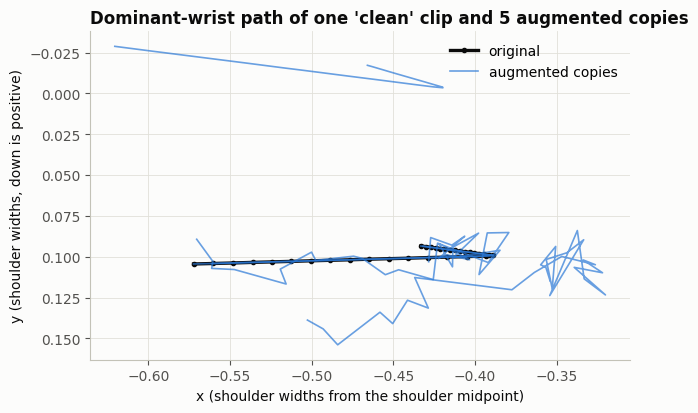

Takeaway: Each copy keeps the shape of the movement while its position, size, rotation and timing change, which is the variation between signers and cameras the model has to ignore.

In [11]:
seed_torch()
gen = torch.Generator(device=DEVICE).manual_seed(SEED)
example = x_train[:1].float().repeat(6, 1, 1)
augmented = torch.cat([example[:1], augment_batch(example[1:], RECIPE_V2, gen)]).cpu().numpy()
wrist = augmented[:, :, 2 * RIGHT.start : 2 * RIGHT.start + 2]  # Dominant wrist, (6, 32, 2).

fig, ax = plt.subplots(figsize=(6.5, 5))
for i, track in enumerate(wrist):
    ok = np.abs(track).sum(axis=1) > 0
    ax.plot(track[ok, 0], track[ok, 1], color=INK if i == 0 else BLUE, linewidth=2.4 if i == 0 else 1.2,
            alpha=1 if i == 0 else 0.7, marker="o" if i == 0 else None, markersize=3,
            label="original" if i == 0 else ("augmented copies" if i == 1 else None))
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set(title=f"Dominant-wrist path of one '{labels[int(y_train[0])]}' clip and 5 augmented copies",
       xlabel="x (shoulder widths from the shoulder midpoint)", ylabel="y (shoulder widths, down is positive)")
ax.legend(loc="best")
plt.tight_layout()
plt.show()
takeaway("Each copy keeps the shape of the movement while its position, size, rotation and timing change, which is the "
         "variation between signers and cameras the model has to ignore.")

## 6. Training

epoch   1/3: train loss 5.242, train top-1 0.040, val top-1 0.007 (62.4 s)


epoch   2/3: train loss 4.323, train top-1 0.163, val top-1 0.043 (59.1 s)


epoch   3/3: train loss 4.296, train top-1 0.142, val top-1 0.080 (61.6 s)
best val top-1 0.080 at epoch 3; 3.1 min of training


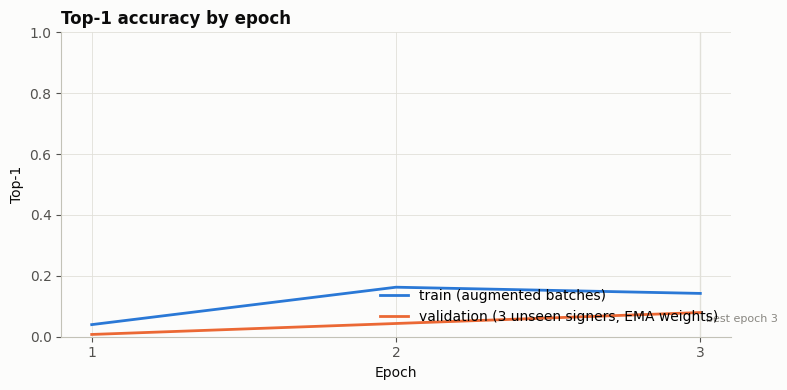

Takeaway: At the selected epoch the model gets 14.2% of augmented training batches right and 8.0% of the validation signers' clips, a 6-point gap; training accuracy is measured on augmented batches and validation on unaugmented clips of new signers.

In [12]:
model, history = train_model(HybridClassifier(), x_train, y_train, x_val, y_val, epochs=EPOCHS, lr=LR,
                             recipe=RECIPE_V2, ema_decay=EMA_DECAY)
best_epoch = int(history["val_top1"].idxmax()) + 1
print(f"best val top-1 {history['val_top1'].max():.3f} at epoch {best_epoch}; "
      f"{history['seconds'].sum() / 60:.1f} min of training")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["epoch"], history["train_top1"], color=BLUE, linewidth=2, label="train (augmented batches)")
ax.plot(history["epoch"], history["val_top1"], color=ORANGE, linewidth=2, label="validation (3 unseen signers, EMA weights)")
ax.axvline(best_epoch, color=GRID, linewidth=1, zorder=0)
ax.annotate(f"best epoch {best_epoch}", (best_epoch, 0.05), xytext=(4, 0), textcoords="offset points", color=MUTED, fontsize=8)
ax.set(title="Top-1 accuracy by epoch", xlabel="Epoch", ylabel="Top-1", ylim=(0, 1))
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
final = history.iloc[best_epoch - 1]
takeaway(f"At the selected epoch the model gets {final['train_top1']:.1%} of augmented training batches right and "
         f"{final['val_top1']:.1%} of the validation signers' clips, a {100 * (final['train_top1'] - final['val_top1']):.0f}-point gap; "
         "training accuracy is measured on augmented batches and validation on unaugmented clips of new signers.")

## 7. Test results on unseen signers

The test split is scored once, with the epoch chosen on validation.

In [13]:
test_logits = predict_logits(model, x_test)
predicted = test_logits.argmax(1).cpu().numpy()
truth = y_test.cpu().numpy()
correct = predicted == truth
low, high = bootstrap_ci(correct)


def macro_f1(truth, predicted, n=250):
    """Unweighted mean over classes of the F1 score."""
    tp = np.bincount(truth[predicted == truth], minlength=n).astype(float)
    precision = tp / np.maximum(np.bincount(predicted, minlength=n), 1)
    recall = tp / np.maximum(np.bincount(truth, minlength=n), 1)
    return float(np.mean(np.where(precision + recall > 0, 2 * precision * recall / np.maximum(precision + recall, 1e-12), 0)))


test_top1 = correct.mean()
print(f"test top-1 {test_top1:.3f} (95% CI {low:.3f}-{high:.3f} over clips), top-5 {top_k(test_logits, y_test, 5):.3f}, "
      f"macro F1 {macro_f1(truth, predicted):.3f}, {len(truth):,} clips")
by_signer = pd.Series(correct).groupby(test_rows["participant_id"].to_numpy()).agg(["mean", "size"])
by_signer.columns = ["top-1", "clips"]
by_signer.round(3)

test top-1 0.083 (95% CI 0.067-0.099 over clips), top-5 0.208, macro F1 0.041, 1,006 clips


,top-1,clips
30680,0.060,166
37779,0.098,256
49445,0.073,288
62590,0.091,296


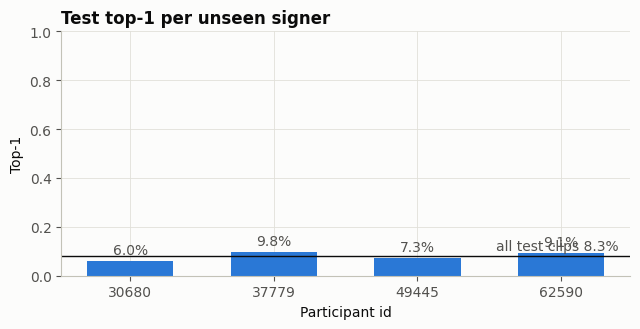

Takeaway: Accuracy ranges from 6.0% to 9.8% across the four test signers, a 4-point spread from who is signing.

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
bars = ax.bar(by_signer.index.astype(str), by_signer["top-1"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in by_signer["top-1"]], padding=3, color=INK_2)
ax.axhline(test_top1, color=INK, linewidth=1)
ax.annotate(f"all test clips {test_top1:.1%}", (3.4, test_top1), xytext=(0, 4), textcoords="offset points", ha="right", color=INK_2)
ax.set(title="Test top-1 per unseen signer", xlabel="Participant id", ylabel="Top-1", ylim=(0, 1))
plt.tight_layout()
plt.show()
takeaway(f"Accuracy ranges from {by_signer['top-1'].min():.1%} to {by_signer['top-1'].max():.1%} across the four test signers, "
         f"a {100 * (by_signer['top-1'].max() - by_signer['top-1'].min()):.0f}-point spread from who is signing.")

## 8. Per-sign accuracy

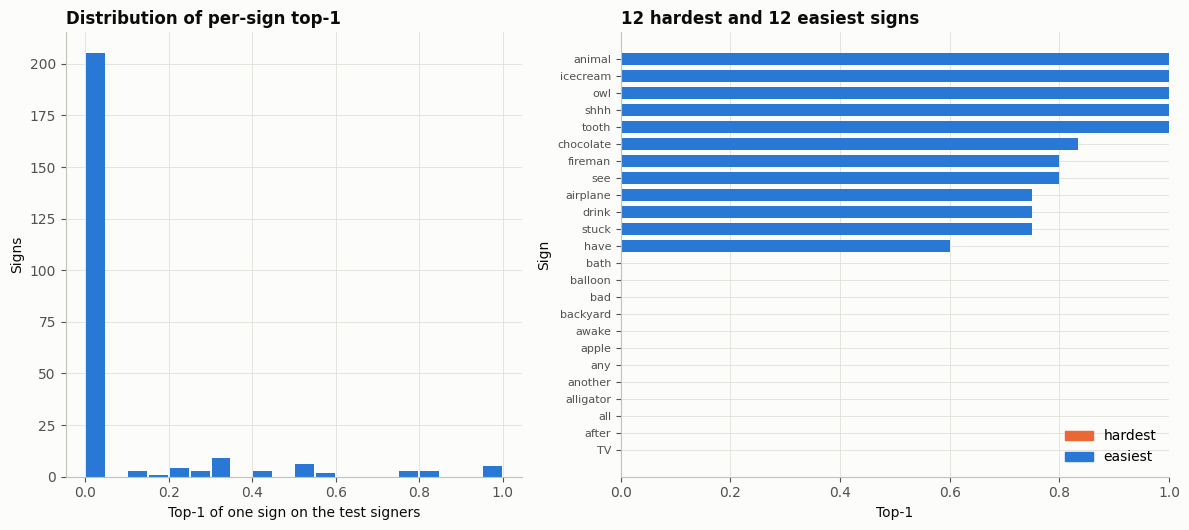

Takeaway: Per-sign top-1 runs from 0% ('TV') to 100% ('animal'); 225 signs fall below 40% and 5 reach 90% or more.

In [15]:
per_sign = pd.DataFrame({"sign": [labels[i] for i in truth], "correct": correct}).groupby("sign")["correct"].agg(["mean", "size"])
per_sign.columns = ["top-1", "clips"]
ends = pd.concat([per_sign.nsmallest(12, "top-1"), per_sign.nlargest(12, "top-1").iloc[::-1]])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1, 1.2]})
ax1.hist(per_sign["top-1"], bins=20, range=(0, 1), color=BLUE, rwidth=0.9)
ax1.set(title="Distribution of per-sign top-1", xlabel="Top-1 of one sign on the test signers", ylabel="Signs")
ax2.barh(range(len(ends)), ends["top-1"], color=[ORANGE] * 12 + [BLUE] * 12, height=0.75)
ax2.set_yticks(range(len(ends)), ends.index, fontsize=8)
ax2.set(title="12 hardest and 12 easiest signs", xlabel="Top-1", ylabel="Sign", xlim=(0, 1))
ax2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
           labels=["hardest", "easiest"], loc="lower right")
plt.tight_layout()
plt.show()
takeaway(f"Per-sign top-1 runs from {per_sign['top-1'].min():.0%} ('{per_sign['top-1'].idxmin()}') to "
         f"{per_sign['top-1'].max():.0%} ('{per_sign['top-1'].idxmax()}'); {(per_sign['top-1'] < 0.4).sum()} signs fall below 40% "
         f"and {(per_sign['top-1'] >= 0.9).sum()} reach 90% or more.")

## 9. The most common confusions

A confusion pair counts test clips of sign A predicted as sign B. When reading the list, look for pairs that share a handshape or a location: the model sees only x and y of the hands and the pose, with no mouth shapes and no depth.

,true,predicted,clips,share of the true sign
0,where,airplane,7,0.778
1,dad,fireman,6,1.000
2,dirty,table,5,1.000
3,yourself,better,4,0.800
4,dryer,toy,4,0.571
5,head,home,4,1.000
6,bed,hair,4,1.000
7,awake,wake,4,0.800
8,doll,icecream,4,0.667
9,milk,yellow,4,1.000


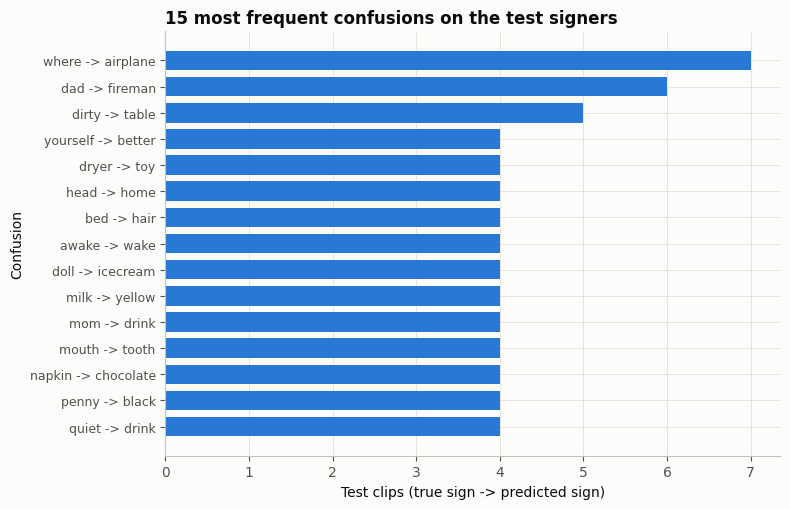

Takeaway: The most frequent error, 'where' read as 'airplane', takes 78% of 'where' clips; the top 15 pairs account for 7% of all 923 test errors.

In [16]:
pairs = pd.DataFrame({"true": [labels[i] for i in truth], "predicted": [labels[i] for i in predicted]})
pairs = pairs[pairs["true"] != pairs["predicted"]].value_counts().rename("clips").reset_index()
pairs["share of the true sign"] = pairs["clips"] / pairs["true"].map(per_sign["clips"])
top = pairs.head(15)
display(top.round(3))

fig, ax = plt.subplots(figsize=(8, 5.2))
names = [f"{t} -> {p}" for t, p in zip(top["true"], top["predicted"])]
ax.barh(range(len(top))[::-1], top["clips"], color=BLUE, height=0.75)
ax.set_yticks(range(len(top))[::-1], names, fontsize=9)
ax.set(title="15 most frequent confusions on the test signers", xlabel="Test clips (true sign -> predicted sign)", ylabel="Confusion")
plt.tight_layout()
plt.show()
lead = top.iloc[0]
takeaway(f"The most frequent error, '{lead['true']}' read as '{lead['predicted']}', takes {lead['share of the true sign']:.0%} of "
         f"'{lead['true']}' clips; the top 15 pairs account for {top['clips'].sum() / (~correct).sum():.0%} of all "
         f"{(~correct).sum():,} test errors.")

In [17]:
both_ways = pairs.assign(pair=[" / ".join(sorted(p)) for p in zip(pairs["true"], pairs["predicted"])]).groupby("pair")["clips"].sum()
both_ways.sort_values(ascending=False).head(10).rename("clips, both directions").to_frame()

,"clips, both directions"
pair,
airplane / where,7
dad / fireman,6
awake / wake,5
dirty / table,5
chocolate / napkin,4
black / penny,4
dryer / toy,4
drink / mom,4
drink / quiet,4


The trained weights and label map are saved to the notebook's output, so you can load them without retraining. Notebook 5 exports this architecture to ONNX.

In [18]:
torch.save({"state_dict": model.state_dict(), "labels": labels, "test_top1": float(test_top1)}, WORK_DIR / "hybrid_asl_signs.pt")
print(f"saved hybrid_asl_signs.pt ({(WORK_DIR / 'hybrid_asl_signs.pt').stat().st_size / 1e6:.1f} MB)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 7.2), gridspec_kw={"width_ratios": [1, 1.1]})
ax1.plot(history["epoch"], history["train_top1"], color=BLUE, linewidth=2.5, label="train")
ax1.plot(history["epoch"], history["val_top1"], color=ORANGE, linewidth=2.5, label="validation (unseen signers)")
ax1.set(xlabel="Epoch", ylabel="Top-1", ylim=(0, 1), title="Training")
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax1.legend(loc="lower right")
n_cover = min(10, len(top))
ax2.barh(range(n_cover)[::-1], top["clips"].head(n_cover), color=BLUE, height=0.75)
ax2.set_yticks(range(n_cover)[::-1], names[:n_cover], fontsize=11)
ax2.set(xlabel="Test clips", title="Most frequent confusions")
fig.suptitle(f"CNN + Transformer hybrid: {test_top1:.1%} top-1 on 4 unseen signers ({len(truth):,} clips, 250 signs)",
             fontweight="bold", fontsize=16, x=0.02, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.94))
save_cover(fig)
plt.close(fig)

saved hybrid_asl_signs.pt (13.7 MB)


## 10. What we found

In [19]:
display(Markdown(
    f"Trained for {len(history)} epochs ({history['seconds'].sum() / 60:.0f} minutes on {DEVICE.type.upper()}), the hybrid scores "
    f"{test_top1:.1%} top-1 (95% CI {low:.1%} to {high:.1%}) and {top_k(test_logits, y_test, 5):.1%} top-5 on {len(truth):,} clips "
    f"from four signers it never saw, against 68.5% for the repository's 150-epoch runs on the same signers. "
    f"The four test signers range from {by_signer['top-1'].min():.1%} to {by_signer['top-1'].max():.1%}, and per-sign top-1 from "
    f"{per_sign['top-1'].min():.0%} to {per_sign['top-1'].max():.0%}. "
    f"The 15 most frequent confusion pairs hold {top['clips'].sum() / (~correct).sum():.0%} of the errors, led by "
    f"'{lead['true']}' read as '{lead['predicted']}'."
))

Trained for 3 epochs (3 minutes on CPU), the hybrid scores 8.3% top-1 (95% CI 6.7% to 9.9%) and 20.8% top-5 on 1,006 clips from four signers it never saw, against 68.5% for the repository's 150-epoch runs on the same signers. The four test signers range from 6.0% to 9.8%, and per-sign top-1 from 0% to 100%. The 15 most frequent confusion pairs hold 7% of the errors, led by 'where' read as 'airplane'.

### Limitations

- One seed and one split. The repository's three seeds differ by 0.2 points; a different set of test signers would move the number more than that (see the per-signer spread above).
- 80 epochs instead of the repository's 150 with early stopping, so the two scores do not come from the same recipe.
- The bootstrap interval resamples clips and treats them as independent, which they are not within a signer.
- Landmarks only: signs that differ by mouth shape or by depth are out of reach for this input.

### Ideas to try

- Average the logits of three seeds; the repository's seed ensemble gains about 2.5 points (`results/model_selection.md`).
- Add the face landmarks around the mouth as extra input and check the confusion pairs above.
- Swap the 17-frame depthwise kernel for 9 or 25 and see whether short signs or long signs benefit.

### The series

- [1. ASL Signs EDA: animating 94k landmark sequences](https://www.kaggle.com/code/swapnilshukla007/asl-signs-eda-animating-94k-landmark-sequences)
- [2. The hand-swap bug: measuring train-serve skew in MediaPipe sign recognition](https://www.kaggle.com/code/swapnilshukla007/the-hand-swap-bug-train-serve-skew-in-asl-models)
- [3. Why random splits overstate sign recognition accuracy](https://www.kaggle.com/code/swapnilshukla007/why-random-splits-overstate-sign-accuracy)
- [5. From PyTorch to the browser: ONNX export, FP16/INT8 quantization and temperature calibration](https://www.kaggle.com/code/swapnilshukla007/pytorch-to-browser-onnx-fp16-int8-calibration)

If this helped, an upvote helps other people find it, and feedback in the comments is welcome.